# Medical Image Classification with Transfer Learning

Chest X-rays, Normal vs Pneumonia. I'm using a pretrained EfficientNet-B0 and fine-tuning it on the images, then using Grad-CAM at the end to see what parts of the X-ray the model actually looked at when making a prediction.

Dataset: Chest X-Ray Images (Pneumonia), originally from Kermany et al., hosted on Kaggle.

## Setup

Standard imports plus a device check. If you're running this in Colab, make sure the runtime is set to GPU (Runtime -> Change runtime type -> GPU), otherwise training will be painfully slow.

In [3]:
import os
import random
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("PyTorch version:", torch.__version__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
PyTorch version: 2.11.0+cu128
GPU: Tesla T4


## Getting the dataset

This dataset lives on Kaggle (`paultimothymooney/chest-xray-pneumonia`), so I need a Kaggle API token to pull it automatically.

Steps (only needed once per Colab session):
1. Go to kaggle.com -> your account settings -> "Create New API Token". This downloads a `kaggle.json` file.
2. Run the cell below, then use the file upload button that appears to upload `kaggle.json`.
3. The rest of the cell downloads and unzips the dataset into `/content/chest_xray`.

There are a couple of other Kaggle mirrors of the same dataset, but they still need an account, so there's no real way around getting a token.

Expected folder structure after this runs:

```
chest_xray/
    train/
        NORMAL/
        PNEUMONIA/
    val/
        NORMAL/
        PNEUMONIA/
    test/
        NORMAL/
        PNEUMONIA/
```

In [4]:
!pip install -q kagglehub

import kagglehub
import os
import shutil

download_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Downloaded to:", download_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Downloaded to: /kaggle/input/chest-xray-pneumonia


In [5]:
DATA_DIR = "/content/chest_xray"

if not os.path.exists(DATA_DIR):
    shutil.copytree(
        os.path.join(download_path, "chest_xray"),
        DATA_DIR
    )

print("Dataset ready at:", DATA_DIR)

Dataset ready at: /content/chest_xray


In [6]:
!pip install -q kaggle

DATA_DIR = "/content/chest_xray"

if not os.path.exists(DATA_DIR):
    !kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content --unzip

# the zip sometimes creates a nested chest_xray/chest_xray folder, so handle that case
nested = "/content/chest_xray/chest_xray"
if os.path.exists(nested):
    DATA_DIR = nested

print("Data directory:", DATA_DIR)
print(os.listdir(DATA_DIR))

Data directory: /content/chest_xray/chest_xray
['val', '.DS_Store', 'test', 'train']


In [7]:
train_dir = os.path.join(DATA_DIR, "train")
val_dir = os.path.join(DATA_DIR, "val")
test_dir = os.path.join(DATA_DIR, "test")

for split_name, split_dir in [("train", train_dir), ("val", val_dir), ("test", test_dir)]:
    assert os.path.exists(split_dir), f"Missing folder: {split_dir}"
    for cls in ["NORMAL", "PNEUMONIA"]:
        cls_dir = os.path.join(split_dir, cls)
        assert os.path.exists(cls_dir), f"Missing folder: {cls_dir}"

print("All expected folders are present.")

All expected folders are present.


In [8]:
def count_images(split_dir):
    counts = {}
    for cls in ["NORMAL", "PNEUMONIA"]:
        cls_dir = os.path.join(split_dir, cls)
        counts[cls] = len([f for f in os.listdir(cls_dir) if not f.startswith(".")])
    return counts

counts_summary = {
    "train": count_images(train_dir),
    "val": count_images(val_dir),
    "test": count_images(test_dir),
}

counts_df = pd.DataFrame(counts_summary).T
counts_df["total"] = counts_df["NORMAL"] + counts_df["PNEUMONIA"]
counts_df

,NORMAL,PNEUMONIA,total
train,1341,3875,5216
val,8,8,16
test,234,390,624


## A quick look at the images

Just want to see what these actually look like before doing anything else. Not making any diagnostic claims here, just eyeballing the data.

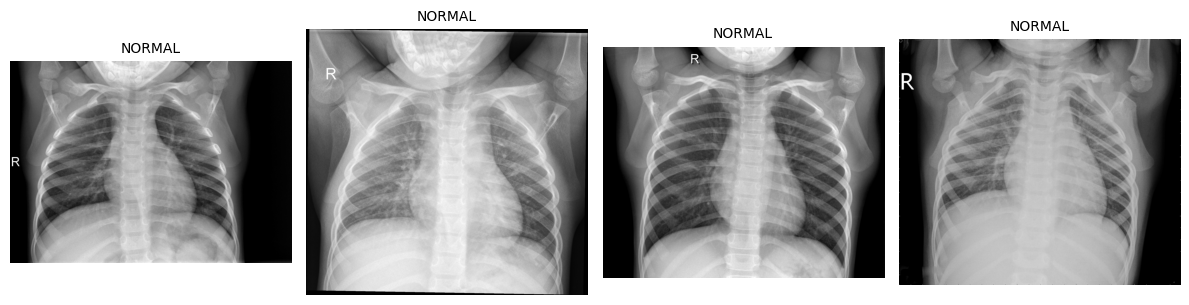

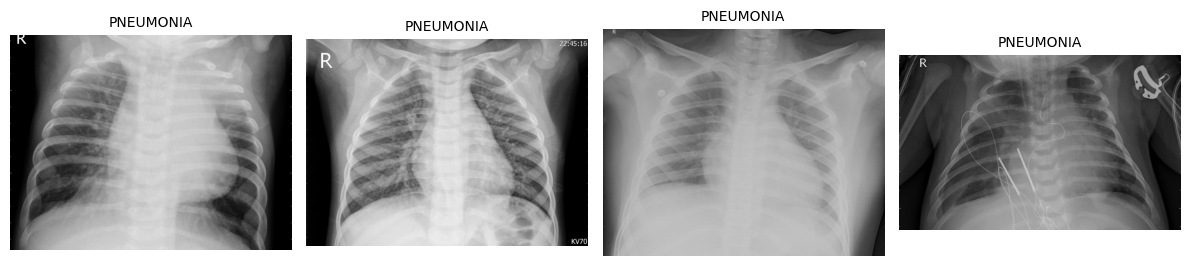

In [9]:
def show_samples(cls, split_dir, n=4):
    cls_dir = os.path.join(split_dir, cls)
    files_list = [f for f in os.listdir(cls_dir) if not f.startswith(".")][:n]
    fig, axes = plt.subplots(1, n, figsize=(12, 3))
    for ax, fname in zip(axes, files_list):
        img = Image.open(os.path.join(cls_dir, fname)).convert("L")
        ax.imshow(img, cmap="gray")
        ax.set_title(cls, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_samples("NORMAL", train_dir)
show_samples("PNEUMONIA", train_dir)

Even without any medical background, the PNEUMONIA images tend to look hazier / less clear in the lung area compared to the NORMAL ones. That's just a visual impression from a few samples, not something to read too much into.

## Class balance

Checking how balanced the training set is before building the loaders.

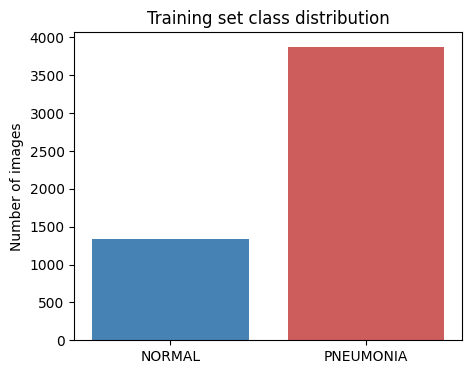

Imbalance ratio (majority/minority): 2.89


In [10]:
train_counts = counts_df.loc["train", ["NORMAL", "PNEUMONIA"]]

plt.figure(figsize=(5, 4))
plt.bar(train_counts.index, train_counts.values, color=["steelblue", "indianred"])
plt.title("Training set class distribution")
plt.ylabel("Number of images")
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

imbalance_ratio = train_counts.max() / train_counts.min()
print(f"Imbalance ratio (majority/minority): {imbalance_ratio:.2f}")

The classes are noticeably imbalanced (more PNEUMONIA images than NORMAL in training), so I'll keep this in mind when I look at accuracy later — recall and F1 per class will matter more than raw accuracy. I'm not applying class weights automatically; I'll decide after seeing the first training run whether the model is biased toward the majority class.

## Preprocessing and augmentation

Using standard ImageNet mean/std since we're starting from ImageNet-pretrained weights. Augmentation is kept light — a horizontal flip and a small rotation. Nothing aggressive like color jitter, since these are grayscale medical images and I don't want to introduce artifacts that don't make sense for X-rays.

In [11]:
IMG_SIZE = 224
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

In [12]:
# images are grayscale, but ImageFolder's default loader converts to RGB, which is what EfficientNet expects
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
val_dataset = datasets.ImageFolder(val_dir, transform=eval_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=eval_transform)

# don't assume which index is which - check it
print("Class to index mapping:", train_dataset.class_to_idx)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Class to index mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Train batches: 163
Val batches: 1
Test batches: 20


In [13]:
# reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# won't be 100% identical across different GPUs, but keeps this run consistent

## Model: EfficientNet-B0

Starting from ImageNet weights, then swapping the classifier head for our 2 classes.

In [14]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

num_classes = 2
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

model = model.to(device)

def count_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("Model: EfficientNet-B0")
print("Trainable parameters:", count_trainable(model))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


Model: EfficientNet-B0
Trainable parameters: 4010110


## Phase 1: train the classifier head only

I froze the feature extractor first so the pretrained weights aren't disturbed right away. Only the new final layer trains in this phase.

In [15]:
for name, param in model.named_parameters():
    if "classifier" not in name:
        param.requires_grad = False

print("Trainable parameters after freezing:", count_trainable(model))

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=1e-3)

Trainable parameters after freezing: 2562


In [16]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            if is_training:
                optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [17]:
EPOCHS_PHASE1 = 4
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(EPOCHS_PHASE1):
    t0 = time.time()
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch+1}/{EPOCHS_PHASE1} | "
          f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} | "
          f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} | "
          f"{time.time()-t0:.1f}s")

Epoch 1/4 | train_loss: 0.2881 train_acc: 0.8919 | val_loss: 0.4107 val_acc: 0.8125 | 91.8s
Epoch 2/4 | train_loss: 0.1868 train_acc: 0.9283 | val_loss: 0.2789 val_acc: 0.8750 | 78.6s
Epoch 3/4 | train_loss: 0.1711 train_acc: 0.9337 | val_loss: 0.3132 val_acc: 0.8125 | 76.3s
Epoch 4/4 | train_loss: 0.1675 train_acc: 0.9316 | val_loss: 0.5153 val_acc: 0.8125 | 76.2s


## Phase 1 training curves

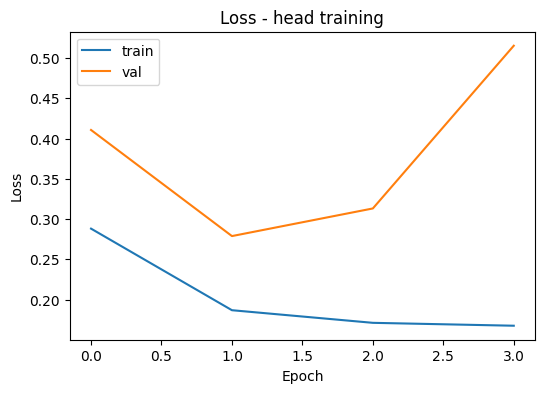

In [18]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.title("Loss - head training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.savefig("figures/training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

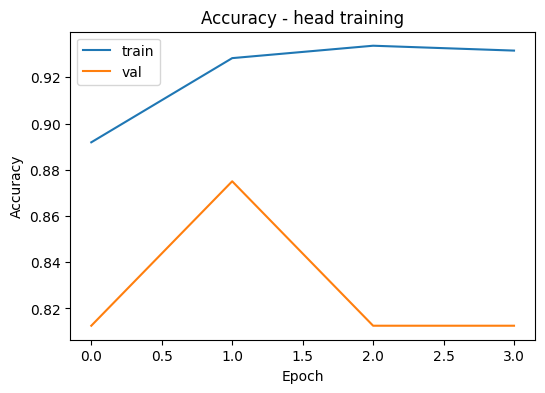

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train")
plt.plot(history["val_acc"], label="val")
plt.title("Accuracy - head training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.savefig("figures/training_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

Worth checking the gap between train and val here - if train accuracy keeps climbing while val flattens or drops, that's overfitting. Probably won't see much of it yet since only the head is training, but good to check again after fine-tuning.

## Phase 2: fine-tuning

Now unfreezing just the last block of EfficientNet-B0, not the whole network, and dropping the learning rate. Early layers already learned generic stuff like edges and textures from ImageNet, so I'd rather leave those alone. If I unfroze everything with a normal learning rate, the first few bad batches could wreck those weights before the model settles in. A lower learning rate just makes the updates gentler.

In [20]:
# unfreeze the last feature block + the classifier
for name, param in model.named_parameters():
    if "features.8" in name or "features.7" in name or "classifier" in name:
        param.requires_grad = True

print("Trainable parameters after partial unfreeze:", count_trainable(model))

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

Trainable parameters after partial unfreeze: 1131954


In [21]:
EPOCHS_PHASE2 = 3
best_val_acc = 0.0
best_model_path = "best_efficientnet_b0.pth"

for epoch in range(EPOCHS_PHASE2):
    t0 = time.time()
    train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Fine-tune epoch {epoch+1}/{EPOCHS_PHASE2} | "
          f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} | "
          f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f} | "
          f"{time.time()-t0:.1f}s")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"  -> saved new best model (val_acc={val_acc:.4f})")

print("Best validation accuracy:", best_val_acc)

Fine-tune epoch 1/3 | train_loss: 0.1230 train_acc: 0.9509 | val_loss: 0.1851 val_acc: 0.8750 | 77.8s
  -> saved new best model (val_acc=0.8750)
Fine-tune epoch 2/3 | train_loss: 0.0946 train_acc: 0.9638 | val_loss: 0.3591 val_acc: 0.8750 | 77.5s
Fine-tune epoch 3/3 | train_loss: 0.0840 train_acc: 0.9693 | val_loss: 0.2045 val_acc: 0.8750 | 78.7s
Best validation accuracy: 0.875


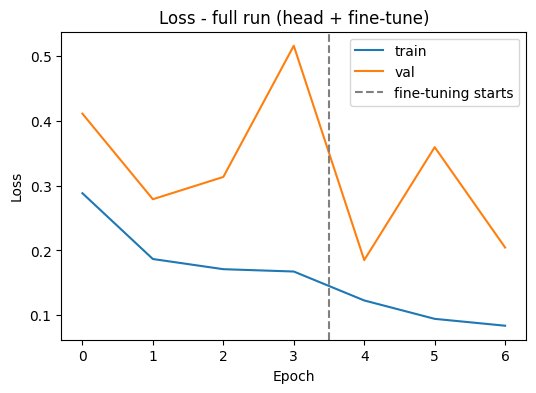

In [22]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.axvline(EPOCHS_PHASE1 - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
plt.title("Loss - full run (head + fine-tune)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Test set evaluation

Loading the best checkpoint (picked by validation accuracy) and running it once on the test set. This is the only time the test set gets touched.

In [23]:
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        preds = probs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())  # probability of PNEUMONIA, index checked below

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs = np.array(all_probs)

class_names = list(train_dataset.class_to_idx.keys())
pneumonia_idx = train_dataset.class_to_idx["PNEUMONIA"]
print("PNEUMONIA index:", pneumonia_idx)  # confirming this matches column 1 used above

PNEUMONIA index: 1


In [24]:
acc = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, pos_label=pneumonia_idx)
recall = recall_score(all_labels, all_preds, pos_label=pneumonia_idx)
f1 = f1_score(all_labels, all_preds, pos_label=pneumonia_idx)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 score:  {f1:.4f}")
print()
print(classification_report(all_labels, all_preds, target_names=class_names))

Accuracy:  0.8702
Precision: 0.8488
Recall:    0.9641
F1 score:  0.9028

              precision    recall  f1-score   support

      NORMAL       0.92      0.71      0.80       234
   PNEUMONIA       0.85      0.96      0.90       390

    accuracy                           0.87       624
   macro avg       0.89      0.84      0.85       624
weighted avg       0.88      0.87      0.87       624



Recall for PNEUMONIA matters more here than for NORMAL, since missing an actual pneumonia case (false negative) is a worse mistake than a false alarm in most real screening contexts. Not making a clinical claim, just noting why I'm not treating all errors as equally bad when reading these numbers.

## Confusion matrix

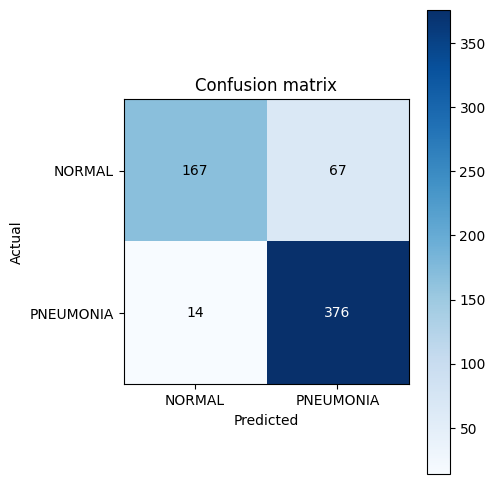

In [25]:
cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(class_names)
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion matrix")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.colorbar(im)
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## ROC-AUC

Using the predicted probability of PNEUMONIA to compute ROC-AUC.

ROC-AUC: 0.9458


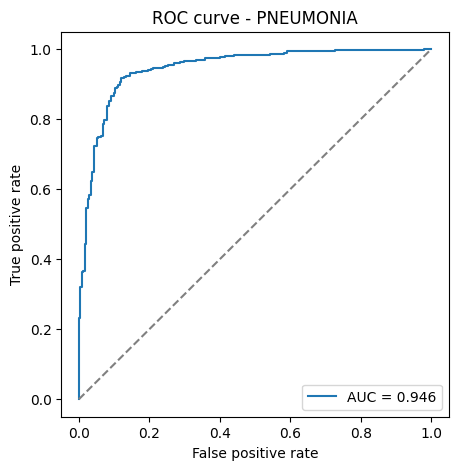

In [26]:
roc_auc = roc_auc_score(all_labels, all_probs)
fpr, tpr, _ = roc_curve(all_labels, all_probs, pos_label=pneumonia_idx)

print(f"ROC-AUC: {roc_auc:.4f}")

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve - PNEUMONIA")
plt.legend()
plt.savefig("figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Sample predictions

Just grabbing a batch from the test loader as-is, not cherry-picking correct ones.

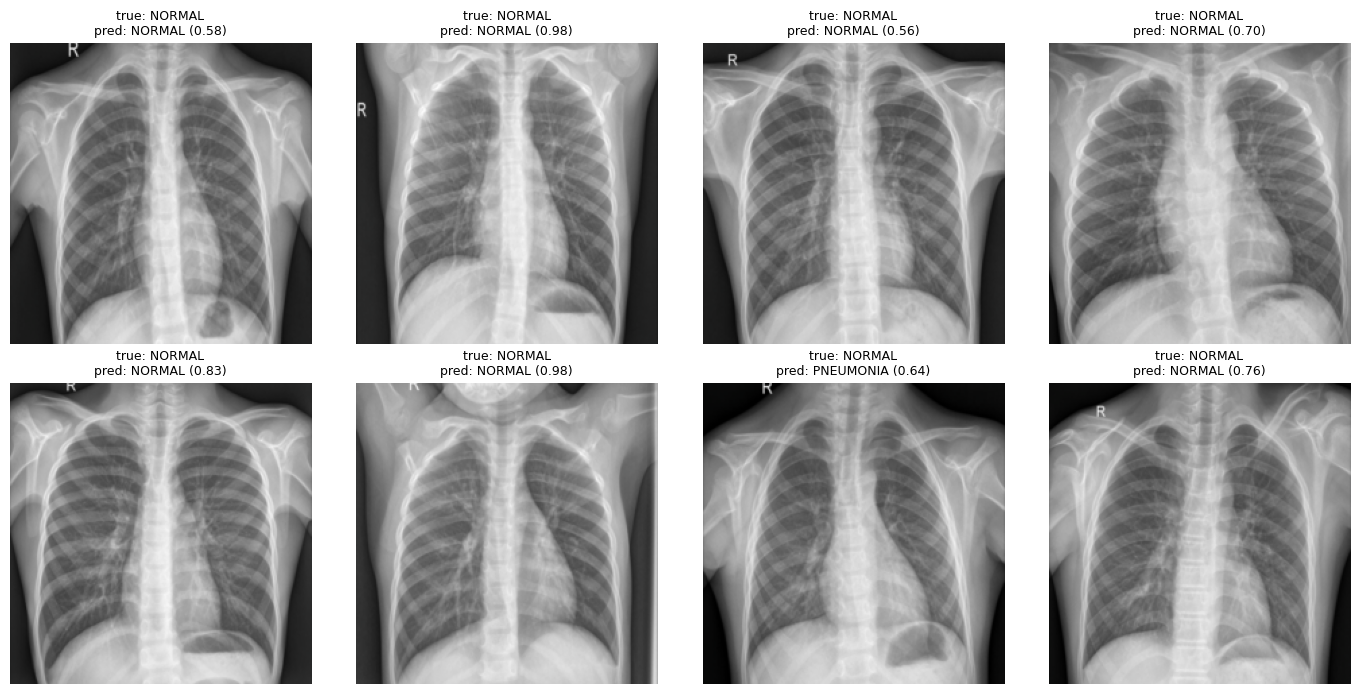

In [27]:
images, labels = next(iter(test_loader))
images_gpu = images.to(device)

with torch.no_grad():
    outputs = model(images_gpu)
    probs = torch.softmax(outputs, dim=1)
    preds = probs.argmax(dim=1)

n_show = 8
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i in range(n_show):
    img = images[i].permute(1, 2, 0).numpy()
    img = img * np.array(imagenet_std) + np.array(imagenet_mean)
    img = np.clip(img, 0, 1)

    true_label = class_names[labels[i].item()]
    pred_label = class_names[preds[i].item()]
    conf = probs[i, preds[i]].item()

    axes[i].imshow(img)
    axes[i].set_title(f"true: {true_label}\npred: {pred_label} ({conf:.2f})", fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Error analysis

Looking specifically at where the model is wrong on the test set, and pulling out a few false positives and false negatives to look at directly.

In [28]:
fp_indices = np.where((all_preds == pneumonia_idx) & (all_labels != pneumonia_idx))[0]
fn_indices = np.where((all_preds != pneumonia_idx) & (all_labels == pneumonia_idx))[0]

print("Number of false positives:", len(fp_indices))
print("Number of false negatives:", len(fn_indices))

Number of false positives: 67
Number of false negatives: 14


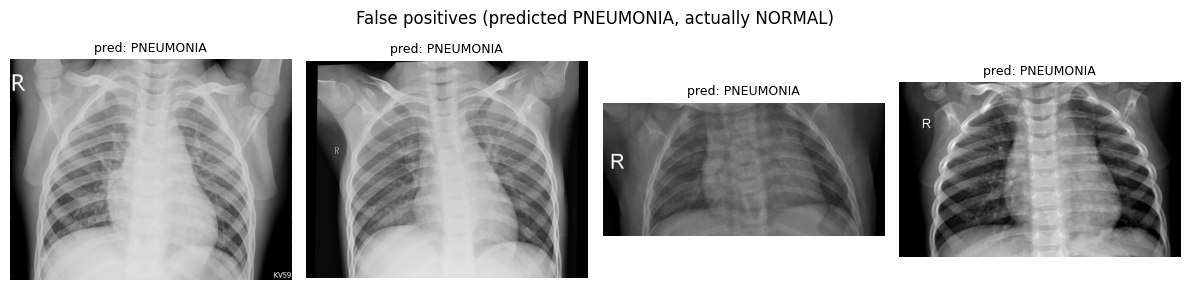

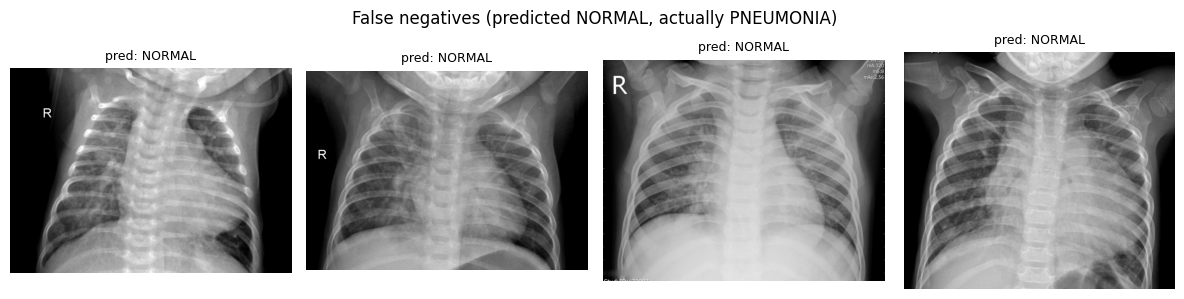

In [29]:
def show_error_examples(indices, title, n=4):
    n = min(n, len(indices))
    if n == 0:
        print(f"No examples for: {title}")
        return
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    if n == 1:
        axes = [axes]
    picked = np.random.choice(indices, size=n, replace=False)
    for ax, idx in zip(axes, picked):
        img_path, true_idx = test_dataset.samples[idx]
        img = Image.open(img_path).convert("L")
        ax.imshow(img, cmap="gray")
        ax.set_title(f"pred: {class_names[all_preds[idx]]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_error_examples(fp_indices, "False positives (predicted PNEUMONIA, actually NORMAL)")
show_error_examples(fn_indices, "False negatives (predicted NORMAL, actually PNEUMONIA)")

Can't say for sure why these got misclassified without a radiologist's read. Some of the false negatives look visually close to the correctly classified NORMAL images, which makes me wonder if the model is picking up on overall brightness/contrast rather than something more localized. Grad-CAM below should give a better idea.

## Grad-CAM

Using `pytorch-grad-cam` instead of writing this by hand, since a correct Grad-CAM implementation for EfficientNet needs the right target layer and hook logic, and there's no reason to reinvent it.

Grad-CAM shows which pixels contributed most to the model's decision. It does **not** prove those pixels are medically meaningful — it just shows what the network was looking at.

In [30]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [39]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# last conv block of EfficientNet-B0 works well as the target layer for Grad-CAM
target_layers = [model.features[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

In [40]:
def get_gradcam_overlay(model, cam, image_tensor):
    input_tensor = image_tensor.unsqueeze(0).to(device)

    grayscale_cam = cam(input_tensor=input_tensor)
    grayscale_cam = grayscale_cam[0]

    img = image_tensor.detach().cpu().permute(1, 2, 0).numpy()

    mean = np.array(imagenet_mean, dtype=np.float32)
    std = np.array(imagenet_std, dtype=np.float32)

    img = img * std + mean
    img = np.clip(img, 0, 1).astype(np.float32)

    overlay = show_cam_on_image(
        img,
        grayscale_cam,
        use_rgb=True
    )

    return img, overlay

# find one NORMAL and one PNEUMONIA prediction from the batch above to show both
normal_pos = np.where(preds.cpu().numpy() == train_dataset.class_to_idx["NORMAL"])[0]
pneumonia_pos = np.where(preds.cpu().numpy() == pneumonia_idx)[0]

example_indices = []
if len(normal_pos) > 0:
    example_indices.append(normal_pos[0])
if len(pneumonia_pos) > 0:
    example_indices.append(pneumonia_pos[0])
# fill up to 4 examples from whatever is left in the batch
remaining = [i for i in range(len(images)) if i not in example_indices]
example_indices += remaining[: max(0, 4 - len(example_indices))]

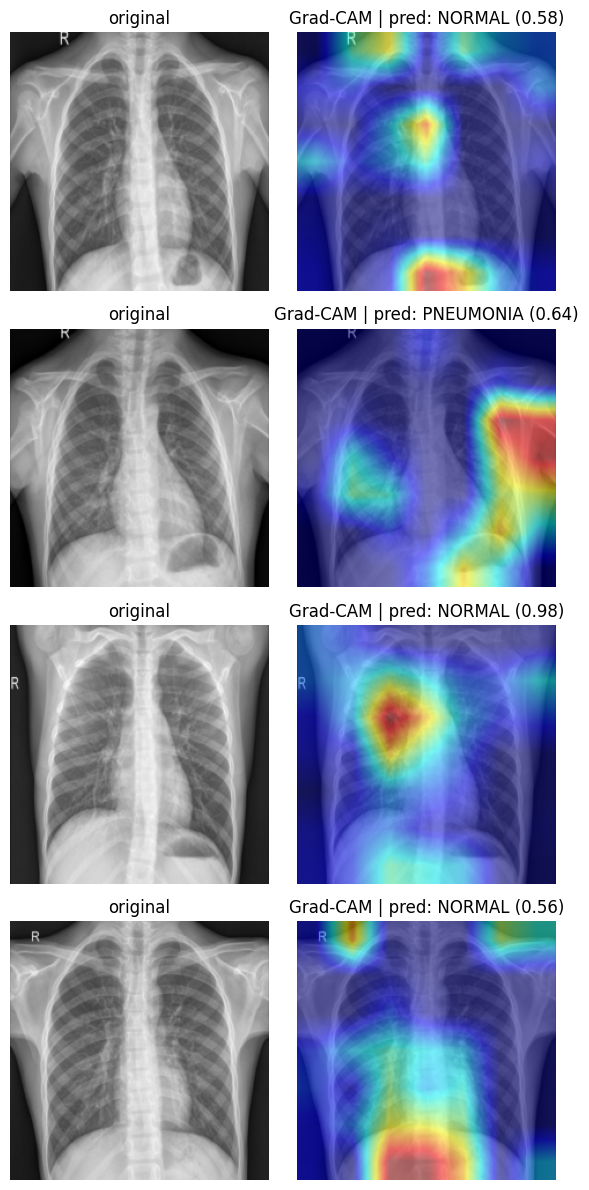

In [41]:
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def get_gradcam_overlay(model, cam, image_tensor, target_class_idx):
    input_tensor = image_tensor.unsqueeze(0).to(device)
    # The GradCAM call requires a 'targets' argument, specifying the class for which to compute the CAM.
    targets = [ClassifierOutputTarget(target_class_idx)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0]

    img = image_tensor.detach().cpu().permute(1, 2, 0).numpy()

    mean = np.array(imagenet_mean, dtype=np.float32)
    std = np.array(imagenet_std, dtype=np.float32)

    img = img * std + mean
    img = np.clip(img, 0, 1).astype(np.float32)

    overlay = show_cam_on_image(
        img,
        grayscale_cam,
        use_rgb=True
    )

    return img, overlay

fig, axes = plt.subplots(len(example_indices), 2, figsize=(6, 3 * len(example_indices)))
if len(example_indices) == 1:
    axes = axes.reshape(1, 2)

for row, idx in enumerate(example_indices):
    # Get the predicted class index to pass to get_gradcam_overlay
    target_class_idx = preds[idx].item()
    orig, overlay = get_gradcam_overlay(model, cam, images[idx], target_class_idx)
    pred_label = class_names[target_class_idx]
    conf = probs[idx, target_class_idx].item()

    axes[row, 0].imshow(orig)
    axes[row, 0].set_title("original")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"Grad-CAM | pred: {pred_label} ({conf:.2f})")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.savefig("figures/gradcam_example.png", dpi=150, bbox_inches="tight")
plt.show()

## Results summary

In [42]:
results_df = pd.DataFrame([{
    "Model": "EfficientNet-B0",
    "Accuracy": acc,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC-AUC": roc_auc,
}])

results_df.to_csv("medical_image_results.csv", index=False)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,EfficientNet-B0,0.870192,0.848758,0.964103,0.902761,0.945759


## Saved files

The `figures/` folder was created earlier when saving the class distribution plot, so everything below just confirms what ended up there.

In [43]:
os.makedirs("figures", exist_ok=True)
print("Files in figures/:")
for f in sorted(os.listdir("figures")):
    print(" -", f)

print()
print("Other saved files:")
for f in [best_model_path, "medical_image_results.csv"]:
    print(" -", f, "exists:" , os.path.exists(f))

Files in figures/:
 - class_distribution.png
 - confusion_matrix.png
 - gradcam_example.png
 - roc_curve.png
 - training_accuracy.png
 - training_loss.png

Other saved files:
 - best_efficientnet_b0.pth exists: True
 - medical_image_results.csv exists: True


## Conclusion

Built from the actual results above, not typed in by hand.

In [44]:
fine_tune_note = (
    "fine-tuning the last block gave a small boost over the head-only model"
    if history["val_acc"][-1] > history["val_acc"][EPOCHS_PHASE1 - 1]
    else "fine-tuning didn't clearly beat the head-only model, at least in this run"
)

conclusion = f"""
EfficientNet-B0 reached {acc:.3f} accuracy on the test set, with precision {precision:.3f},
recall {recall:.3f}, and F1 {f1:.3f} (ROC-AUC: {roc_auc:.3f}).

Looking at the phase 1 vs phase 2 validation curves, {fine_tune_note}.

The confusion matrix above shows {cm[0][1] + cm[1][0]} total misclassifications out of {len(all_labels)}
test images ({len(fp_indices)} false positives, {len(fn_indices)} false negatives). The Grad-CAM
overlays were useful mainly as a sanity check - they show the model attending to areas inside the
lung region rather than something irrelevant like borders or text markers on the scan, though that
alone doesn't prove the features it's using are clinically meaningful.
"""

print(conclusion)


EfficientNet-B0 reached 0.870 accuracy on the test set, with precision 0.849,
recall 0.964, and F1 0.903 (ROC-AUC: 0.946).

Looking at the phase 1 vs phase 2 validation curves, fine-tuning the last block gave a small boost over the head-only model.

The confusion matrix above shows 81 total misclassifications out of 624
test images (67 false positives, 14 false negatives). The Grad-CAM
overlays were useful mainly as a sanity check - they show the model attending to areas inside the
lung region rather than something irrelevant like borders or text markers on the scan, though that
alone doesn't prove the features it's using are clinically meaningful.



## Limitations

- Trained and evaluated on a single dataset/source, so results might not hold on X-rays from a different hospital or scanner.
- Binary classification only (Normal vs Pneumonia) — doesn't distinguish bacterial vs viral pneumonia or other conditions.
- Backbone is ImageNet-pretrained, which is a big domain gap from chest X-rays.
- No external/held-out dataset from a different source was used to check generalization.
- Grad-CAM is an interpretability aid, not proof the model is using medically valid features.
- This is a portfolio/learning project, not a diagnostic tool, and isn't intended for clinical use.